# 05 · Model 3: Random Forest
**Owner:** Sheetal · **Family:** Ensemble (bagging) · **Script:** `models/train_rf.py`

**Why this model for PathSnap?** Bagged decision trees learn non-linear rules and feature interactions (e.g. 'close AND same heading AND near on neighbouring points') without scaling, and averaging many trees reduces variance.

**Strengths:** captures interactions, robust to feature scale and outliers, gives feature importances, strong out-of-the-box.

**Limitations:** large model (about 70 MB with 200 depth-20 trees), slower to fit (about 65 s), and probabilities from vote fractions are less sharp than boosting.

**Loss / objective:** each tree greedily minimises Gini impurity at each split. The forest averages tree probabilities. Class weights are 'balanced_subsample'.

**Protocol (same for all 5 models, `models/common.py`):** 5-fold **GroupKFold by trip** on the 78 clean training trips (trips 54 and 33 excluded) → refit on all of them → evaluate on the 10 student_test trips (every GPS point). Primary metric: **observation-level Top-1 accuracy**. Only one fixed configuration per model: **no grid or random search** (organiser rule). Only the selected model is tuned, with Bayesian optimisation.

In [1]:
import os, sys
# run from the repository root regardless of where the notebook lives
_p = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(_p, "pathsnap")):
    _p = os.path.dirname(_p)
os.chdir(_p); sys.path.insert(0, _p)
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
print("repo root:", os.getcwd())
from models.train_rf import est, cfg
from models.common import run_experiment
from pathsnap.features import FEATURE_COLUMNS
print("hyperparameters:", cfg)
est

repo root: C:\Users\shrey\OneDrive\Documents\ML Hackathon\PathSnap_7_H


hyperparameters: {'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}


,n_estimators,200
,criterion,'gini'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,5
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## Train, cross-validate and evaluate

In [2]:
row, model = run_experiment("random_forest", "Ensemble (bagging)", est, cfg)
pd.Series(row).drop("config_json")

[random_forest] train rows=587,684 trips=78 | test rows=131,630


[random_forest] CV macroF1=0.9209±0.0129 CV top1=0.8719 | test top1=0.8775 macroF1=0.9212 logloss=0.1034 cont=0.9497 | fit 57.0s, infer 53 ms/trip


model                             random_forest
family                       Ensemble (bagging)
cv_macro_f1_mean                       0.920882
cv_macro_f1_std                        0.012897
cv_top1_mean                           0.871877
cv_top1_std                            0.027523
cv_logloss                             0.110321
train_top1                             0.930017
train_macro_f1                         0.950464
test_top1                              0.877505
test_macro_f1                          0.921154
test_precision                         0.816415
test_recall                            0.923584
test_logloss                           0.103394
test_cand_miss_rate                    0.002818
test_route_continuity_clf              0.949697
train_time_s                              56.99
infer_ms_per_trip                         53.13
train_rows                               587684
seed                                         42
dtype: object

In [3]:
log = json.load(open("results/model_runs/random_forest.json"))
folds = pd.DataFrame(log["folds"]); display(folds.round(4))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
folds.plot(x="fold", y=["top1_accuracy", "macro_f1"], marker="o", ax=ax[0]); ax[0].set_title("Per-fold CV scores"); ax[0].set_ylim(0.75, 1)
bars = pd.Series({"train (fit data)": row["train_top1"], "CV (mean)": row["cv_top1_mean"], "student_test": row["test_top1"]})
bars.plot.bar(ax=ax[1], color=["C2", "C0", "C1"]); ax[1].set_ylim(0.75, 1); ax[1].set_title("Top-1: train vs CV vs test (over/underfitting)")
for i, v in enumerate(bars): ax[1].text(i, v + .005, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()

,macro_f1,precision,recall,logloss,top1_accuracy,candidate_miss_rate,fold,fit_s
0,0.9032,0.7968,0.8848,0.1323,0.8332,0.0074,0,42.46
1,0.9362,0.8594,0.9276,0.0929,0.8968,0.0176,1,41.72
2,0.9131,0.8054,0.9066,0.1143,0.8527,0.0165,2,48.34
3,0.9279,0.8336,0.9245,0.0931,0.8879,0.0028,3,57.81
4,0.9241,0.8277,0.9337,0.1191,0.8887,0.0009,4,50.59


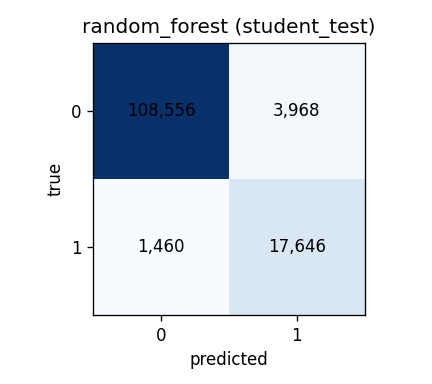

In [4]:
from IPython.display import Image
Image("results/plots/confusion_random_forest.png")

## Feature importances (mean decrease in impurity)

In [5]:
imp = pd.Series(model.feature_importances_, index=FEATURE_COLUMNS).sort_values()
plt.figure(figsize=(7, 5)); imp.plot.barh(); plt.title("Random Forest feature importance")
plt.tight_layout(); plt.savefig("results/plots/rf_importance.png"); plt.show()

In [6]:
r = row
gap = r["train_top1"] - r["cv_top1_mean"]
verdict = "overfitting (large train-CV gap)" if gap > 0.05 else ("mild overfitting" if gap > 0.02 else "no overfitting (train ≈ CV; if anything, high bias)")
print(f"""Student-test results  : Top-1 {r['test_top1']:.4f} | macro F1 {r['test_macro_f1']:.4f} | precision {r['test_precision']:.4f} | recall {r['test_recall']:.4f} | log loss {r['test_logloss']:.4f}
Route continuity (classifier-only argmax): {r['test_route_continuity_clf']:.4f}
CV Top-1 {r['cv_top1_mean']:.4f} ± {r['cv_top1_std']:.4f} | CV macro F1 {r['cv_macro_f1_mean']:.4f} ± {r['cv_macro_f1_std']:.4f}
Train Top-1 {r['train_top1']:.4f} -> train-CV gap {gap:+.4f}: {verdict}
Fit time {r['train_time_s']:.1f} s | inference {r['infer_ms_per_trip']:.0f} ms per trip""")

Student-test results  : Top-1 0.8775 | macro F1 0.9212 | precision 0.8164 | recall 0.9236 | log loss 0.1034
Route continuity (classifier-only argmax): 0.9497
CV Top-1 0.8719 ± 0.0275 | CV macro F1 0.9209 ± 0.0129
Train Top-1 0.9300 -> train-CV gap +0.0581: overfitting (large train-CV gap)
Fit time 57.0 s | inference 53 ms per trip
